# Python Intern Technical Test

## What this is
A progressive test: Python basics -> data structures -> OOP & dataclasses -> data manipulation (pandas) -> visualization -> a small FastAPI backend (+ optional front-end) -> a short system-design question.

## Rules - please read
1. **Use AI freely** (ChatGPT, Claude, Copilot, anything). We use it every day and we expect you to.
2. **But you must be able to explain every line you submit.** After you submit there is a **45-60 min call**: you will walk us through your work, answer "why" questions, predict what happens when we change something, and make a **small live change** to your own code. Code you cannot explain counts against you more than code that is missing.
3. Keep a short log in `AI_LOG.md` (template in the repo): which tool you used for what, one thing the AI got wrong or that you rejected, and one thing you learned.
4. Written answers (the "Your answer" cells) can be in **English or Portuguese**. Keep them short: 2-5 sentences. Your own words, please.
5. If you get stuck, **skip and move on**, and tell us in the notebook what you tried. A partial but understood solution beats a complete mystery.

## Parts
| Part | Topic |
|---|---|
| 1 | Python basics & data structures |
| 2 | Classes, dataclasses, OOP |
| 3 | Data manipulation with pandas |
| 4 | Visualization |
| 5 | FastAPI backend (`app/`) |
| 6 | System design (`DESIGN_ANSWER.md`) |
| 7 | AI log, clean-up, commit |

## How to submit
Fork/clone this repo -> work in a branch -> *Restart kernel & Run All* so the notebook is saved with outputs -> make sure `pytest` runs -> push and send us the link.

In [59]:
import sys, re, math, dataclasses
from collections import Counter, defaultdict
from dataclasses import dataclass, field, asdict, replace
from enum import Enum
from pathlib import Path
from typing import Iterable, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT))          # so `import app` works from the notebook


def check(label, fn):
    """Self-check helper: prints OK / FAIL and never stops the notebook."""
    try:
        ok = bool(fn())
    except Exception as e:             # a check can fail because your code raised
        print(f"[FAIL] {label}   ({type(e).__name__}: {e})")
        return False
    print(("[ OK ] " if ok else "[FAIL] ") + label)
    return ok


def raises(exc, fn):
    """True if fn() raises `exc`."""
    try:
        fn()
    except exc:
        return True
    except Exception:
        return False
    return False


print("root:", ROOT, "| data files:", sorted(p.name for p in DATA.glob("*")))

root: c:\Users\mateu\OneDrive\Documentos\GitHub\intern-test | data files: ['patients_raw.txt', 'plate_layout.csv', 'readings_raw.csv']


---
# Part 1 - Python basics & data structures

A 96-well plate has 8 rows (`A`-`H`) and 12 columns (`1`-`12`). Our lab software numbers wells **column by column**:
`A1, B1, ... H1, A2, B2, ... H12`  (index 0 -> `A1`, index 7 -> `H1`, index 8 -> `A2`, index 95 -> `H12`).

### 1.1 Well names
Implement both functions. They must raise `ValueError` on invalid input, and `well_index` must tolerate letter case and surrounding spaces.

In [37]:
ROWS = "ABCDEFGH"
N_COLS = 12


def well_name(index: int) -> str:
    """0 -> 'A1', 7 -> 'H1', 8 -> 'A2', 95 -> 'H12'. ValueError if index is outside 0..95."""
    raise NotImplementedError


def well_index(name: str) -> int:
    """Inverse of well_name. ' b3 ' -> 17. ValueError for 'I1', 'A13', 'A0', '', 'A01'..."""
    raise NotImplementedError

1.1 Well names - resposta

In [61]:
ROWS = "ABCDEFGH"
N_COLS = 12
WELL_RE = re.compile(r"^[A-H](?:[1-9]|1[0-2])$")

def well_name(index: int) -> str:
    if not 0 <= index <= 95:                       # fora de 0..95?
        raise ValueError(f"invalid well index: {index!r}")
    row = ROWS[index % 8]
    col = index// 8 +1
    return f"{row}{col}"


def well_index(name: str) -> int:
    if not isinstance(name, str):
        raise ValueError(f"invalid well: {name!r}")
    well = name.strip().upper()          # tolera espaço e caixa
    if not WELL_RE.match(well):
        raise ValueError(f"invalid well: {name!r}")
    row = ROWS.index(well[0])               # posição da letra
    col = int(well[1:])                      # número da coluna
    return (col - 1) * 8 + row

In [39]:
check("well_name(0) == 'A1'", lambda: well_name(0) == "A1")
check("well_name(8) == 'A2'", lambda: well_name(8) == "A2")
check("well_name(95) == 'H12'", lambda: well_name(95) == "H12")
check("well_name(96) raises", lambda: raises(ValueError, lambda: well_name(96)))
check("well_name(-1) raises", lambda: raises(ValueError, lambda: well_name(-1)))
check("well_index(' b3 ') == 17", lambda: well_index(" b3 ") == 17)
check("round trip for all 96 wells", lambda: all(well_index(well_name(i)) == i for i in range(96)))
check("invalid wells raise", lambda: all(raises(ValueError, lambda w=w: well_index(w)) for w in ["I1", "A13", "A0", "", "A01", "11"]))

[ OK ] well_name(0) == 'A1'
[ OK ] well_name(8) == 'A2'
[ OK ] well_name(95) == 'H12'
[ OK ] well_name(96) raises
[ OK ] well_name(-1) raises
[ OK ] well_index(' b3 ') == 17
[ OK ] round trip for all 96 wells
[ OK ] invalid wells raise


True

### 1.2 Parsing a messy patient list
`data/patients_raw.txt` is a list exported by another system, one `sample_id, well` per line. Look at the file first - it has comments, blank lines, odd spacing/casing and some bad lines on purpose.

Write `parse_patient_lines(lines)` returning `(valid, errors)`:
* `valid`: list of `(sample_id, well)` - sample id exactly as written (just stripped), well normalised (`' e3'` -> `'E3'`).
* `errors`: list of `(line_number, stripped_line, reason)` - `line_number` is 1-based **in the original file** (comments and blanks count).
* Blank lines and lines starting with `#` are ignored silently.
* A line is an **error** (and skipped) if: it doesn't have exactly 2 comma-separated fields, the sample id is empty, the well is invalid, or the well was already used by an earlier valid line.

In [40]:
def parse_patient_lines(lines: Iterable[str]):
    """Return (valid, errors) as described above."""
    raise NotImplementedError

1.2 Parsing a messy patient list - resposta

In [41]:
def parse_patient_lines(lines: Iterable[str]):
    valid, errors = [], []
    used_wells = set()

    for line_no, raw_line in enumerate(lines, start=1):
        line = raw_line.strip()
        if not line or line.startswith("#"):
            continue

        parts = line.split(",")
        if len(parts) != 2:
            errors.append((line_no, line, "expected exactly 2 fields"))
            continue

        sample_id, well_raw = parts[0].strip(), parts[1].strip()
        if not sample_id:
            errors.append((line_no, line, "empty sample id"))
            continue

        try:
            well = well_name(well_index(well_raw))
        except ValueError:
            errors.append((line_no, line, f"invalid well: {well_raw!r}"))
            continue

        if well in used_wells:
            errors.append((line_no, line, f"duplicate well: {well}"))
            continue

        used_wells.add(well)
        valid.append((sample_id, well))

    return valid, errors

In [42]:
lines = (DATA / "patients_raw.txt").read_text(encoding="utf-8").splitlines()
valid, errors = parse_patient_lines(lines)
print(len(valid), "valid;", len(errors), "errors")
for e in errors:
    print("  line", e[0], "->", e[2])

check("7 valid lines", lambda: len(valid) == 7)
check("pat_003 keeps its case, well normalised", lambda: ("pat_003", "E3") in valid)
check("errors point at the right original lines", lambda: [e[0] for e in errors] == [8, 9, 10, 11, 12, 13])
check("no duplicate wells in valid", lambda: len({w for _, w in valid}) == len(valid))

7 valid; 6 errors
  line 8 -> duplicate well: F3
  line 9 -> invalid well: 'I1'
  line 10 -> invalid well: 'A13'
  line 11 -> expected exactly 2 fields
  line 12 -> empty sample id
  line 13 -> expected exactly 2 fields
[ OK ] 7 valid lines
[ OK ] pat_003 keeps its case, well normalised
[ OK ] errors point at the right original lines
[ OK ] no duplicate wells in valid


True

### 1.3 Data structures
Write these three small functions (no libraries needed):

In [43]:
def group_by_column(wells: list) -> dict:
    """['A1','B1','A2'] -> {1: ['A1','B1'], 2: ['A2']}  (keep input order inside each list)."""
    raise NotImplementedError


def find_duplicates(ids: list) -> set:
    """Return the ids that appear more than once."""
    raise NotImplementedError


def invert(mapping: dict) -> dict:
    """{'PAT1': 'A1', 'PAT2': 'A1', 'PAT3': 'B1'} -> {'A1': ['PAT1', 'PAT2'], 'B1': ['PAT3']}"""
    raise NotImplementedError

1.3 Data structures - resposta

In [44]:
def group_by_column(wells: list) -> dict:
    groups = defaultdict(list)
    for well in wells:
        col = int(well[1:])
        groups[col].append(well)
    return dict(groups)


def find_duplicates(ids: list) -> set:
    counts = Counter(ids)
    return {item for item, n in counts.items() if n > 1}


def invert(mapping: dict) -> dict:
    inverted = defaultdict(list)
    for sample_id, well in mapping.items():
        inverted[well].append(sample_id)
    return dict(inverted)

In [45]:
check("group_by_column", lambda: group_by_column(["A1", "B1", "A2"]) == {1: ["A1", "B1"], 2: ["A2"]})
check("group_by_column empty", lambda: group_by_column([]) == {})
check("find_duplicates", lambda: find_duplicates(["a", "b", "a", "c", "c", "c"]) == {"a", "c"})
check("find_duplicates none", lambda: find_duplicates(["a", "b"]) == set())
check("invert", lambda: invert({"PAT1": "A1", "PAT2": "A1", "PAT3": "B1"}) == {"A1": ["PAT1", "PAT2"], "B1": ["PAT3"]})

[ OK ] group_by_column
[ OK ] group_by_column empty
[ OK ] find_duplicates
[ OK ] find_duplicates none
[ OK ] invert


True

**Your answer - lists, tuples, sets, dicts.** For each of the four, say *when you would pick it* and give **one concrete example from the plate/patient domain** (e.g. "I'd use a ___ to store ___ because ___"). 2 sentences each.

> **list:** _Eu utilizaria list para casos em que é preciso manter a ordem, não é necessário buscar um valor pelo nome e basta percorrer os itens. Um exemplo disso seriam os wells de A1 a H12 na ordem da placa, pois são percorridos item a item e não é necessário buscar por um nome, como aconteceria em um dict._
>
> **tuple:** _Eu utilizaria tuple para casos em que os dados não devem mudar depois de criados e cada posição tem um papel diferente, como por exemplo o par (sample_id, well) da lista de pacientes, pois é um dado fixo e, se for preciso mudar, crio um par novo._
>
> **set:** _Eu utilizaria set para verificar se um valor já apareceu e evitar repetições, sem parar o processo. Por exemplo, na lista de pacientes, os wells que já apareceram ficam guardados no set, e assim eu detecto quando um deles se repete._
>
> **dict:** _Eu utilizaria dict para casos em que preciso buscar algo específico pela chave, sem percorrer todos os itens. Por exemplo, na lista de pacientes, posso guardar o well de cada paciente para achar onde ele está pelo nome, ou guardar a amostra de cada well para saber qual está em cada well pelo nome do well._

### 1.4 Find the bugs
Both functions below look fine but are wrong. For each: write a minimal call that **shows the bug**, then fix it and explain the cause in one sentence.

In [46]:
def add_sample(sample_id, well, registry=[]):
    registry.append((sample_id, well))
    return registry


def last_n_wells(wells, n):
    """Return the last n wells (all of them if n > len(wells), none if n == 0)."""
    return wells[len(wells) - n + 1:]

In [47]:
# show the bugs here (before fixing), then fix the functions above and re-run the checks
check("add_sample doesn't leak between calls", lambda: add_sample("a", "A1") != add_sample("b", "B1") and len(add_sample("c", "C1")) == 1)
check("last_n_wells(5 items, 2)", lambda: last_n_wells(list("ABCDE"), 2) == ["D", "E"])
check("last_n_wells n == 0", lambda: last_n_wells(list("ABCDE"), 0) == [])
check("last_n_wells n > len", lambda: last_n_wells(list("ABC"), 7) == ["A", "B", "C"])

[FAIL] add_sample doesn't leak between calls
[FAIL] last_n_wells(5 items, 2)
[ OK ] last_n_wells n == 0
[ OK ] last_n_wells n > len


True

1.4 Find the bugs - corrigido

In [48]:
def add_sample(sample_id, well, registry=None):
    if registry is None:
        registry = []
    registry.append((sample_id, well))
    return registry


def last_n_wells(wells, n):
    return wells[max(len(wells) - n, 0):]

In [49]:
check("add_sample doesn't leak between calls", lambda: add_sample("a", "A1") != add_sample("b", "B1") and len(add_sample("c", "C1")) == 1)
check("last_n_wells(5 items, 2)", lambda: last_n_wells(list("ABCDE"), 2) == ["D", "E"])
check("last_n_wells n == 0", lambda: last_n_wells(list("ABCDE"), 0) == [])
check("last_n_wells n > len", lambda: last_n_wells(list("ABC"), 7) == ["A", "B", "C"])

[ OK ] add_sample doesn't leak between calls
[ OK ] last_n_wells(5 items, 2)
[ OK ] last_n_wells n == 0
[ OK ] last_n_wells n > len


True

**Your answer - bugs.** What was wrong in each function, and why did it behave that way?

> `add_sample`: o erro é que o valor padrão de `registry` é uma lista, o que faz o valor da call anterior se manter na call seguinte, em vez de gerar uma lista nova a cada call. Isso acontece porque o `registry=[]` é criado somente na definição da função, e todas as calls compartilham essa mesma lista.
>
> `last_n_wells`: o erro é que o `return` devolvia uma posição depois da que deveria. Além disso, quando `n` era maior que o tamanho da lista, em vez de devolvê-la inteira, ele começava a fatia a partir de um índice negativo, que conta de trás para frente (por exemplo, `-1` é o último valor, `-2` é o penúltimo, e assim por diante).

---
# Part 2 - Classes, dataclasses & OOP

### 2.0 Warm-up: what a dataclass gives you
Read and run this. A `@dataclass` writes `__init__`, `__repr__` and `__eq__` for you from the annotated fields.

In [50]:
@dataclass
class Reagent:
    name: str
    volume_ul: float
    lot: str = "n/a"
    notes: list = field(default_factory=list)   # a mutable default MUST use default_factory (`= []` raises ValueError)


r = Reagent("Wash buffer", 1500.0)
print(r)                                          # auto __repr__
print(r == Reagent("Wash buffer", 1500.0))        # auto __eq__ (field by field)
print(asdict(r))                                  # -> plain dict
print(replace(r, lot="L42"))                      # copy with one field changed

Reagent(name='Wash buffer', volume_ul=1500.0, lot='n/a', notes=[])
True
{'name': 'Wash buffer', 'volume_ul': 1500.0, 'lot': 'n/a', 'notes': []}
Reagent(name='Wash buffer', volume_ul=1500.0, lot='L42', notes=[])


### 2.1 `Sample` - a (frozen) dataclass
Build `Sample` with `@dataclass(frozen=True)`:

| field | type | default |
|---|---|---|
| `sample_id` | `str` | - |
| `well` | `str` | - |
| `sample_type` | `SampleType` | `SampleType.patient` |
| `dilution` | `int` | `1` |
| `tags` | `tuple` | `()` |

Behaviour:
* `well` is **normalised on creation** (`'c2 '` -> `'C2'`) and must be a valid well (`ValueError` otherwise). Reuse `well_name/well_index` from Part 1.
* `dilution` must be `>= 1` (`ValueError` otherwise).
* property `plate_index` -> the column-major index of the well (`C2` -> `10`).
* property `is_control` -> `True` only for negative/positive controls.
* Two samples with the same field values must be equal, and be usable as dict keys / in sets.

In [5]:
class SampleType(str, Enum):
    blank = "blank"
    standard = "standard"
    neg_control = "neg_control"
    pos_control = "pos_control"
    patient = "patient"


@dataclass(frozen=True)
class Sample:
    sample_id: str
    well: str
    sample_type: SampleType = SampleType.patient
    dilution: int = 1
    tags: tuple = ()

    def __post_init__(self):
        well = well_name(well_index(self.well))
        object.__setattr__(self, "well", well)
        if self.dilution < 1:
            raise ValueError(f"dilution must be >= 1, got {self.dilution!r}")

    @property
    def plate_index(self) -> int:
        return well_index(self.well)

    @property
    def is_control(self) -> bool:
        return self.sample_type in (SampleType.neg_control, SampleType.pos_control)

In [52]:
a = Sample("X", "a1")
check("well normalised", lambda: a.well == "A1")
check("defaults", lambda: a.sample_type is SampleType.patient and a.dilution == 1 and a.tags == ())
check("equality by value", lambda: a == Sample("X", "A1"))
check("hashable / set-able", lambda: len({a, Sample("X", "A1"), Sample("Y", "A1")}) == 2)
check("frozen", lambda: raises(dataclasses.FrozenInstanceError, lambda: setattr(a, "well", "B1")))
check("replace() gives a modified copy", lambda: replace(a, well="B1").well == "B1" and a.well == "A1")
check("plate_index", lambda: Sample("X", "C2").plate_index == 10)
check("is_control", lambda: Sample("N", "A2", SampleType.neg_control).is_control and not a.is_control)
check("invalid well -> ValueError", lambda: raises(ValueError, lambda: Sample("X", "Z9")))
check("dilution 0 -> ValueError", lambda: raises(ValueError, lambda: Sample("X", "A1", dilution=0)))
check("asdict works", lambda: asdict(a)["well"] == "A1")

[ OK ] well normalised
[ OK ] defaults
[ OK ] equality by value
[ OK ] hashable / set-able
[ OK ] frozen
[ OK ] replace() gives a modified copy
[ OK ] plate_index
[ OK ] is_control
[ OK ] invalid well -> ValueError
[ OK ] dilution 0 -> ValueError
[ OK ] asdict works


True

### 2.2 The same thing as a plain class
Now write `LegacySample`: **a normal class** (no `@dataclass`) with the same behaviour as `Sample` for: construction + well normalisation + dilution check, `__repr__`, `__eq__`, `__hash__`, and the two properties. (It does not need to be frozen.)

In [53]:
class LegacySample:
    def __init__(self, sample_id, well, sample_type=SampleType.patient, dilution=1, tags=()):
        if dilution < 1:
            raise ValueError(f"dilution must be >= 1, got {dilution!r}")
        self.sample_id = sample_id
        self.well = well_name(well_index(well))
        self.sample_type = sample_type
        self.dilution = dilution
        self.tags = tags

    def _key(self):
        return (self.sample_id, self.well, self.sample_type, self.dilution, self.tags)

    def __repr__(self):
        return (f"LegacySample(sample_id={self.sample_id!r}, well={self.well!r}, "f"sample_type={self.sample_type!r}, dilution={self.dilution!r}, "f"tags={self.tags!r})")

    def __eq__(self, other):
        if not isinstance(other, LegacySample):
            return NotImplemented
        return self._key() == other._key()

    def __hash__(self):
        return hash(self._key())

    @property
    def plate_index(self) -> int:
        return well_index(self.well)

    @property
    def is_control(self) -> bool:
        return self.sample_type in (SampleType.neg_control, SampleType.pos_control)

In [54]:
b = LegacySample("X", " a1 ")
check("well normalised", lambda: b.well == "A1")
check("equality by value", lambda: b == LegacySample("X", "A1"))
check("different objects with same data hash equally", lambda: hash(b) == hash(LegacySample("X", "A1")))
check("not equal to other data", lambda: b != LegacySample("Y", "A1"))
check("repr shows the values", lambda: "sample_id='X'" in repr(b) and "'A1'" in repr(b))
check("plate_index / is_control", lambda: LegacySample("N", "C2", SampleType.neg_control).plate_index == 10 and LegacySample("N", "C2", SampleType.neg_control).is_control)
check("dilution 0 -> ValueError", lambda: raises(ValueError, lambda: LegacySample("X", "A1", dilution=0)))

[ OK ] well normalised
[ OK ] equality by value
[ OK ] different objects with same data hash equally
[ OK ] not equal to other data
[ OK ] repr shows the values
[ OK ] plate_index / is_control
[ OK ] dilution 0 -> ValueError


True

**Your answer - dataclass vs class.**

> 1. List what `@dataclass` generated for you that you had to write by hand in `LegacySample`: O `@dataclass` gerou para mim a definição dos campos e dos valores padrão (`__init__`), a forma como o objeto aparece no `print` (`__repr__`), a comparação entre objetos (`__eq__`) e a geração do hash do objeto (`__hash__`, vindo do `frozen=True`).
>
> 2. In `Sample.__post_init__`, why can't you simply write `self.well = ...`? What did you do instead (or what would you do)? No `__post_init__` eu não posso escrever apenas `self.well = ...`, pois a classe é `frozen`, o que faz com que o `__setattr__` chamado por `self.well = ...` bloqueie a mudança de valores. Para contornar isso, utilizei manualmente `object.__setattr__(self, "well", well)`, que chama o método original e não a versão gerada pelo `frozen`, a qual levanta o `FrozenInstanceError`.
>
> 3. Give one situation *in a project like ours* where you'd still choose a plain class over a dataclass: Eu usaria uma classe escrita manualmente quando ela não serve só para guardar dados, mas tem estado interno que muda e métodos que o modificam, como uma classe que vai recebendo amostras ao longo do tempo. Também a usaria quando preciso de condições mais específicas no `__init__`, porque a classe manual me dá mais controle sobre isso.

### 2.3 `Plate` - a class that holds samples
Build `Plate`, which stores `Sample`s by well. Requirements:

* **class attributes** `ROWS` and `N_COLS` (shared by all plates)
* `__init__(self, name)` -> instance attribute `name`, and private storage of samples keyed by well
* property `n_wells` -> `96` (computed from the class attributes)
* `assign(sample)` -> store it; `ValueError` if that well is already taken
* `get(well)` -> the `Sample` in that well (well can be any case/spacing) or `None`
* `free_wells()` -> list of empty wells in plate (column-major) order
* `@classmethod from_samples(name, samples)` -> build and fill a plate
* `@staticmethod is_valid_well(name)` -> `bool` (never raises)
* dunder methods: `__len__` (number of assigned samples), `__contains__(well)`, `__iter__` (samples in **plate order**, not insertion order), `__repr__` -> `Plate('P2', 2/96 wells)`

In [62]:
class Plate:
    ROWS = "ABCDEFGH"
    N_COLS = 12

    def __init__(self, name):
        self.name = name
        self._samples = {}

    @property
    def n_wells(self) -> int:
        return len(self.ROWS) * self.N_COLS

    def assign(self, sample):
        if sample.well in self._samples:
            raise ValueError(f"well {sample.well} is already taken")
        self._samples[sample.well] = sample

    def get(self, well):
        try:
            return self._samples.get(well_name(well_index(well)))
        except ValueError:
            return None

    def free_wells(self):
        return [well_name(i) for i in range(self.n_wells) if well_name(i) not in self._samples]

    @classmethod
    def from_samples(cls, name, samples):
        plate = cls(name)
        for sample in samples:
            plate.assign(sample)
        return plate

    @staticmethod
    def is_valid_well(name) -> bool:
        try:
            well_index(name)
            return True
        except ValueError:
            return False

    def __len__(self):
        return len(self._samples)

    def __contains__(self, well):
        return self.is_valid_well(well) and well_name(well_index(well)) in self._samples

    def __iter__(self):
        for well in sorted(self._samples, key=well_index):
            yield self._samples[well]

    def __repr__(self):
        return f"Plate({self.name!r}, {len(self)}/{self.n_wells} wells)"

In [63]:
p = Plate("P1")
s = Sample("PAT_001", "c2")
p.assign(s)
check("n_wells == 96, len == 1", lambda: p.n_wells == 96 and len(p) == 1)
check("get() is case/space tolerant", lambda: p.get(" c2 ") == s and p.get("D2") is None)
check("'C2' in plate", lambda: "c2" in p and "D2" not in p and "ZZ" not in p)
check("assigning a taken well raises", lambda: raises(ValueError, lambda: p.assign(Sample("OTHER", "C2"))))
check("free_wells", lambda: len(p.free_wells()) == 95 and p.free_wells()[0] == "A1" and "C2" not in p.free_wells())
p2 = Plate.from_samples("P2", [Sample("a", "H12"), Sample("b", "A1")])
check("from_samples + iteration in plate order", lambda: [x.well for x in p2] == ["A1", "H12"])
check("repr", lambda: repr(p2) == "Plate('P2', 2/96 wells)")
check("is_valid_well never raises", lambda: Plate.is_valid_well("A1") and not Plate.is_valid_well("Q9") and not Plate.is_valid_well(None))
check("class attrs shared, instance attrs not", lambda: Plate.ROWS == "ABCDEFGH" and p.name != p2.name)

[ OK ] n_wells == 96, len == 1
[ OK ] get() is case/space tolerant
[ OK ] 'C2' in plate
[ OK ] assigning a taken well raises
[ OK ] free_wells
[ OK ] from_samples + iteration in plate order
[ OK ] repr
[ OK ] is_valid_well never raises
[ OK ] class attrs shared, instance attrs not


True

### 2.4 Predict, then explain
**Before running the next cell**, write what you think it prints, in the markdown cell below it. Then run it, explain what happened and fix the class (`BatchFixed`).

In [65]:
class Batch:
    samples = []                       # <- look closely

    def __init__(self, name):
        self.name = name

    def add(self, sample_id):
        self.samples.append(sample_id)


b1, b2 = Batch("first"), Batch("second")
b1.add("PAT_001")
print(b2.samples)

['PAT_001']


> **My prediction (written before running):** Uma lista com `PAT_001`.
>
> **What actually happened and why:** Como eu previ, o `print` mostrou uma lista com `PAT_001` em vez de uma lista vazia. Isso aconteceu pelo mesmo motivo da 1.4 (`registry=[]`): a lista `samples = []` é criada uma única vez, quando a classe é definida, e é um atributo da classe. Por isso, todas as instâncias usam a mesma lista.

In [66]:
class BatchFixed:

    def __init__(self, name):
        self.name = name
        self.samples = []

    def add(self, sample_id):
        self.samples.append(sample_id)


b1, b2 = BatchFixed("first"), BatchFixed("second")
b1.add("PAT_001")
print(b2.samples)

[]


In [67]:
f1, f2 = BatchFixed("first"), BatchFixed("second")
f1.add("PAT_001")
check("BatchFixed instances don't share samples", lambda: f1.samples == ["PAT_001"] and f2.samples == [])

[ OK ] BatchFixed instances don't share samples


True

### 2.5 Vocabulary, with your own code
Fill the table using **`Plate`** (from 2.3) as the source of every example - name the exact line/member and say in a few words what makes it that kind of thing.

| Concept | Example in `Plate` | What makes it that? |
|---|---|---|
| class attribute | `ROWS` (linha 2) | É definido no corpo da classe, fora de qualquer método, e é compartilhado por todas as placas. |
| instance attribute | `self.name` (linha 6) | É criado com `self.` dentro do `__init__`, então cada objeto tem o seu próprio valor. |
| method | `assign` | É uma função da classe que recebe a própria instância (`self`) como primeiro parâmetro e atua sobre os dados daquela placa. |
| `@property` | `n_wells` (linha 9) | O `@property` transforma o método em atributo calculado, que é acessado sem parênteses. |
| `@classmethod` | `from_samples` (linha 27) | Recebe a classe (`cls`) em vez da instância e funciona como construtor alternativo. |
| `@staticmethod` | `is_valid_well` (linha 33) | Não recebe `self` nem `cls`, porque não precisa de dados da placa nem da classe. |


---
# Part 3 - Data manipulation with pandas

Two files in `data/`:
* `plate_layout.csv` - what is in each of the 96 wells (`well, sample_id, sample_type, std_conc`).
* `readings_raw.csv` - what the reader exported, **long format**: one row per `(well, analyte)` with `mfi` (signal) and `bead_count` (how many beads were measured). There are 4 analytes (`AN_A` ... `AN_D`). It is **messy on purpose**.

### Calling rules  *(follow these exactly)*
1. **Clean:** well names -> stripped + upper-case; `mfi` -> number (decimal comma `"23,5"` -> `23.5`; anything unreadable such as `"OOR >"` or empty -> `NaN`); drop **exact duplicate rows**. After cleaning, `(well, analyte)` must be unique (384 rows).
2. **Join** the layout on `well`.
3. **Blank subtraction:** for each analyte, `blank_mean` = mean `mfi` of the `blank` wells (ignore NaN). `net_mfi = mfi - blank_mean`. Do **not** clip negatives.
4. A reading is **valid** if `mfi` is not NaN **and** `bead_count >= 35`.
5. **Cutoff per analyte** = `mean(net_mfi) + 3 * std(net_mfi, ddof=1)` computed over the **valid** `neg_control` wells of that analyte. If fewer than 2 valid neg-control readings exist, the cutoff is undefined.
6. **Call** per row: `INVALID` if the reading is not valid (or the cutoff is undefined), else `POS` if `net_mfi > cutoff`, else `NEG`.
7. **Run QC:** the run is valid only if, for every analyte, there is at least one valid `pos_control` reading and **all** valid `pos_control` readings are `POS`.

### 3.0 Explore

In [70]:
raw = pd.read_csv(DATA / "readings_raw.csv")
layout = pd.read_csv(DATA / "plate_layout.csv")
display(raw.head(8))
raw.info()
display(layout.sample_type.value_counts())

,well,analyte,mfi,bead_count
0,H8,AN_D,17.9,58
1,H7,AN_A,24.3,81
2,H12,AN_C,16.8,101
3,C4,AN_A,"23,5",89
4,D1,AN_C,15527.2,81
5,F11,AN_B,26.7,100
6,G12,AN_C,29.2,67
7,B4,AN_B,23.4,123


<class 'pandas.DataFrame'>
RangeIndex: 387 entries, 0 to 386
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   well        387 non-null    str  
 1   analyte     387 non-null    str  
 2   mfi         383 non-null    str  
 3   bead_count  387 non-null    int64
dtypes: int64(1), str(3)
memory usage: 12.2 KB


sample_type
patient        82
standard        6
neg_control     4
blank           2
pos_control     2
Name: count, dtype: int64

**Your answer - data quality.** List every data-quality problem you found in `readings_raw.csv` (at least 5) and, next to each, how you detected it (which pandas call / what you looked at).

> 1. A coluna `mfi` está como texto em vez de número, o que impede fazer contas utilizando-a. Encontrei com `raw.info()`, que mostrou o tipo como `str`/`object` nessa coluna.
>
> 2. Alguns valores de `mfi` estão usando vírgula em decimais (por exemplo `"23,5"`). Encontrei com `pd.to_numeric(raw.mfi, errors="coerce")`, vendo quais linhas viraram `NaN` mesmo tendo um valor escrito nelas.
>
> 3. Existem valores que estão fora da faixa de leitura (`"OOR >"`), que não são números e não podem ser convertidos. Apareceram nas mesmas linhas que viraram `NaN` no `pd.to_numeric(raw.mfi, errors="coerce")`.
>
> 4. Existem valores vazios em `mfi`. Encontrei com `raw.isna().sum()`, que mostrou todos os nulos da coluna.
>
> 5. Alguns nomes de poço têm letra minúscula (por exemplo `a1` e `g11`). Encontrei com `raw[raw.well != raw.well.str.upper()]`.
>
> 6. Alguns nomes de poço têm espaços no começo ou no fim. Encontrei com `raw[raw.well != raw.well.str.strip()]`.
>
> 7. Algumas linhas estão duplicadas, o que explica as 387 linhas em vez das 384 esperadas (96 wells × 4 analytes). Encontrei com `raw.duplicated().sum()`, que deu 3.

### 3.1 Clean

In [72]:
def clean_readings(raw: pd.DataFrame) -> pd.DataFrame:
    """Rule 1. Must not modify `raw` in place."""
    df = raw.copy()
    df["well"] = df["well"].str.strip().str.upper()
    df["mfi"] = (
        df["mfi"].astype("string").str.strip().str.replace(",", ".", regex=False)
    )
    df["mfi"] = pd.to_numeric(df["mfi"], errors="coerce").astype(float)
    return df.drop_duplicates().reset_index(drop=True)


clean = clean_readings(raw)

In [73]:
check("384 rows (96 wells x 4 analytes)", lambda: len(clean) == 384)
check("(well, analyte) is unique", lambda: not clean.duplicated(["well", "analyte"]).any())
check("all wells valid", lambda: clean.well.map(Plate.is_valid_well).all())
check("mfi is numeric", lambda: pd.api.types.is_float_dtype(clean.mfi))
check("6 unusable mfi values became NaN (4 empty + 2 'OOR >')", lambda: clean.mfi.isna().sum() == 6)
check("input untouched", lambda: len(raw) == 387)

[ OK ] 384 rows (96 wells x 4 analytes)
[ OK ] (well, analyte) is unique
[ OK ] all wells valid
[ OK ] mfi is numeric
[ OK ] 6 unusable mfi values became NaN (4 empty + 2 'OOR >')
[ OK ] input untouched


True

### 3.2 Join the layout

In [80]:
df = clean.merge(layout[["well", "sample_id", "sample_type"]], on="well", how="left")

In [81]:
check("still 384 rows", lambda: len(df) == 384)
check("every row has a sample_type", lambda: df.sample_type.notna().all())

[ OK ] still 384 rows
[ OK ] every row has a sample_type


True

### 3.3 - 3.5 Blank subtraction, cutoffs, calls

In [84]:
# 3.3 blank_mean: Series indexed by analyte. Then add the column df["net_mfi"].
blank_mean = df[df.sample_type == "blank"].groupby("analyte")["mfi"].mean()
df["net_mfi"] = df["mfi"] - df["analyte"].map(blank_mean)

# 3.4 valid readings + cutoffs: Series indexed by analyte
MIN_BEADS = 35
df["valid"] = df["mfi"].notna() & (df["bead_count"] >= MIN_BEADS)
neg = df[(df.sample_type == "neg_control") & df["valid"]].groupby("analyte")["net_mfi"]
cutoffs = (neg.mean() + 3 * neg.std(ddof=1)).where(neg.count() >= 2).reindex(blank_mean.index)

# 3.5 the call per row -> add df["call"] with values "POS" / "NEG" / "INVALID"
cutoff_row = df["analyte"].map(cutoffs)
df["call"] = np.where(
    ~df["valid"] | cutoff_row.isna(),
    "INVALID",
    np.where(df["net_mfi"] > cutoff_row, "POS", "NEG"),
)
results = df

In [85]:
print(cutoffs.round(1).to_dict())
print(results.call.value_counts().to_dict())
check("blank_mean has 4 analytes", lambda: len(blank_mean) == 4)
check("cutoffs match the rules (+-0.1)", lambda: all(abs(cutoffs[k] - v) < 0.1 for k, v in {'AN_A': 30.6, 'AN_B': 34.5, 'AN_C': 16.7, 'AN_D': 35.0}.items()))
check("call counts: 295 NEG / 78 POS / 11 INVALID", lambda: results.call.value_counts().to_dict() == {'NEG': 295, 'POS': 78, 'INVALID': 11})
check("blank wells are NEG or INVALID, never POS", lambda: not ((results.sample_type == "blank") & (results.call == "POS")).any())

{'AN_A': 30.6, 'AN_B': 34.5, 'AN_C': 16.7, 'AN_D': 35.0}
{'NEG': 295, 'POS': 78, 'INVALID': 11}
[ OK ] blank_mean has 4 analytes
[ OK ] cutoffs match the rules (+-0.1)
[ OK ] call counts: 295 NEG / 78 POS / 11 INVALID
[ OK ] blank wells are NEG or INVALID, never POS


True

### 3.6 Summaries

Build `summary`: **index = analyte**, columns `n_valid`, `n_pos`, `pos_rate` (%, rounded to 1 decimal), considering **patient wells with a valid reading only**. Then compute `run_valid` (rule 7) as a Python `bool`.

In [86]:
pat = results[(results.sample_type == "patient") & results["valid"]]

summary = pat.groupby("analyte").agg(
    n_valid=("call", "size"),
    n_pos=("call", lambda s: (s == "POS").sum()),
)
summary["pos_rate"] = (summary["n_pos"] / summary["n_valid"] * 100).round(1)

pos = results[(results.sample_type == "pos_control") & results["valid"]]

qc = pos.groupby("analyte")["call"].agg(
    n="size",
    n_pos=lambda s: (s == "POS").sum(),
)
ok = ((qc["n"] >= 1) & (qc["n"] == qc["n_pos"])).reindex(blank_mean.index, fill_value=False)
run_valid = bool(ok.all())

In [87]:
display(summary)
check("summary index/columns", lambda: list(summary.index) == ["AN_A", "AN_B", "AN_C", "AN_D"] and {"n_valid", "n_pos", "pos_rate"} <= set(summary.columns))
check("AN_A numbers", lambda: summary.loc["AN_A", "n_valid"] == 78 and summary.loc["AN_A", "n_pos"] == 14)
check("run_valid is a bool and True for this plate", lambda: run_valid is True)

,n_valid,n_pos,pos_rate
analyte,,,
AN_A,78,14,17.9
AN_B,78,11,14.1
AN_C,82,12,14.6
AN_D,79,9,11.4


[ OK ] summary index/columns
[ OK ] AN_A numbers
[ OK ] run_valid is a bool and True for this plate


True

**Your answer - judgement calls.** Where did the rules force a choice that could change the result (e.g. negative net values, `ddof=1`, treating `"OOR >"` as missing, only 2 blank wells...)? Pick **two** and explain what you'd ask the lab scientist before shipping this to production.

> 1. Tratar `"OOR >"` como ausente(NaN). A regra pega esse valor e o transforma em `NaN`, e a leitura se torna `INVALID`. Porém, `OOR` significa que o sinal excedeu o limite superior do equipamento, ou seja, o valor é muito alto e pode ser um positivo forte. Descartá-lo pode fazer o laboratório perder justamente os casos mais claros. Eu perguntaria ao cientista se `"OOR >"` deve ser tratado como `INVALID` ou como positivo.
>
> 2. Usar só 2 blank wells. O `blank_mean` é a média de somente dois valores, e eles podem ser bem diferentes (no `AN_A`, `7.3` e `21.8`). Esse número é subtraído de todas as medições do analyte, então um branco ruim ou contaminado desloca todos os `net_mfi` e, consequentemente, o `cutoff` e as chamadas. Eu perguntaria se dois brancos são suficientes e o que fazer quando há uma diferença muito grande entre eles.

---
# Part 4 - Visualization

Use matplotlib (or seaborn/plotly if you prefer - add it to `requirements.txt`). Charts must be readable by a lab technician: titles, axis labels, units, legend/colorbar.

### 4.1 Plate heatmap
Write `plot_plate(results, analyte, ax=None)` that draws the **8 x 12 plate** (rows `A`-`H` top to bottom, columns 1-12 left to right) coloured by `net_mfi` on a **log colour scale** (negatives clipped to 1 *for display only*). Mark the well types (e.g. letters `B`/`S`/`N`/`P` for blank/standard/neg/pos) and mark `INVALID` wells so they are not mistaken for low signal. Return the `Axes`.

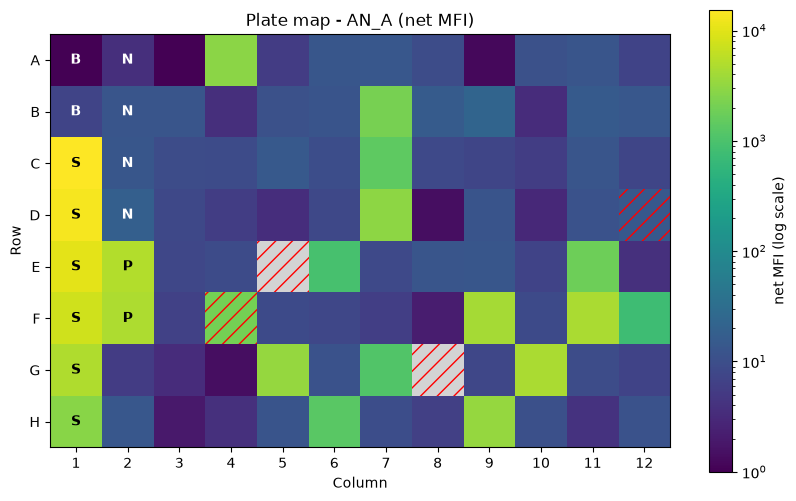

In [90]:
from matplotlib.patches import Rectangle

TYPE_LETTER = {"blank": "B", "standard": "S", "neg_control": "N",
               "pos_control": "P", "patient": ""}


def plot_plate(results: pd.DataFrame, analyte: str, ax=None):
    d = results[results["analyte"] == analyte]
    n_rows = len(ROWS)
    grid = np.full((n_rows, N_COLS), np.nan)
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 6))
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("lightgrey")

    cells = []
    for r in d.itertuples():
        col, row = divmod(well_index(r.well), n_rows)
        if pd.notna(r.net_mfi):
            grid[row, col] = max(r.net_mfi, 1)
        cells.append((row, col, r))

    norm = LogNorm(vmin=1, vmax=np.nanmax(grid))
    im = ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, norm=norm)

    for row, col, r in cells:
        if r.call == "INVALID":
            ax.add_patch(Rectangle((col - .5, row - .5), 1, 1, fill=False,
                                   hatch="//", edgecolor="red", linewidth=0))
        letter = TYPE_LETTER.get(r.sample_type, "")
        if letter:
            v = grid[row, col]
            color = "white" if np.isnan(v) or norm(v) < 0.5 else "black"
            ax.text(col, row, letter, ha="center", va="center",
                    color=color, fontweight="bold")

    ax.set_xticks(range(N_COLS)); ax.set_xticklabels(range(1, N_COLS + 1))
    ax.set_yticks(range(n_rows)); ax.set_yticklabels(list(ROWS))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title(f"Plate map - {analyte} (net MFI)")
    ax.figure.colorbar(im, ax=ax, label="net MFI (log scale)")
    return ax


ax = plot_plate(results, "AN_A")
plt.show()

In [91]:
check("returns an Axes with an image", lambda: hasattr(ax, "images") and len(ax.images) == 1)
check("grid is 8 x 12", lambda: ax.images[0].get_array().shape == (8, 12))
check("axes have a title and a colorbar", lambda: ax.get_title() != "" and len(ax.figure.axes) >= 2)

[ OK ] returns an Axes with an image
[ OK ] grid is 8 x 12
[ OK ] axes have a title and a colorbar


True

### 4.2 Standard curve
The six `standard` wells have known concentrations (`std_conc`, pg/mL). Write `plot_standard_curve(results, layout, analyte)`: scatter of `std_conc` vs `net_mfi` on **log-log** axes with a straight-line fit in log10 space (`np.polyfit`). Return `(slope, intercept, r2)`.

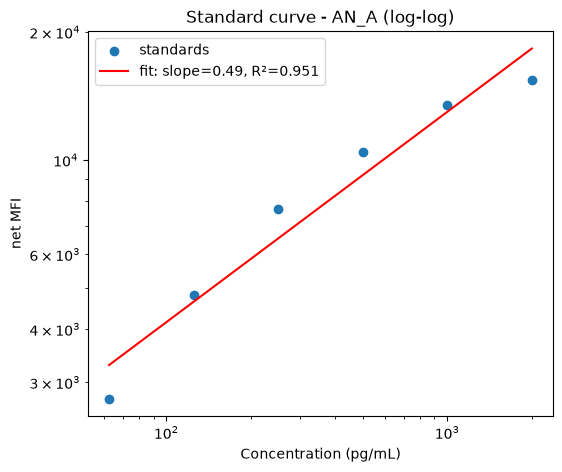

slope=0.49 intercept=2.63 r2=0.951


In [102]:
def plot_standard_curve(results, layout, analyte):
    std = results[
        (results["analyte"] == analyte)
        & (results["sample_type"] == "standard")
        & results["valid"]
    ]
    std = std.merge(layout[["well", "std_conc"]], on="well", how="left")
    std = std[std["net_mfi"] > 0]

    x = np.log10(std["std_conc"])
    y = np.log10(std["net_mfi"])

    slope, intercept = np.polyfit(x, y, 1)
    y_hat = slope * x + intercept
    ss_res = ((y - y_hat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(std["std_conc"], std["net_mfi"], label="standards")
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(10 ** xs, 10 ** (slope * xs + intercept), color="red",
            label=f"fit: slope={slope:.2f}, R²={r2:.3f}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Concentration (pg/mL)")
    ax.set_ylabel("net MFI")
    ax.set_title(f"Standard curve - {analyte} (log-log)")
    ax.legend()
    return float(slope), float(intercept), float(r2)


slope, intercept, r2 = plot_standard_curve(results, layout, "AN_A")
plt.show()
print(f"slope={slope:.2f} intercept={intercept:.2f} r2={r2:.3f}")

In [98]:
check("returns three numbers", lambda: all(np.isfinite([slope, intercept, r2])))
check("slope is positive and r2 in (0.8, 1]", lambda: slope > 0 and 0.8 < r2 <= 1)

[ OK ] returns three numbers
[ OK ] slope is positive and r2 in (0.8, 1]


True

### 4.3 Patients vs cutoff
One figure, 4 panels (one per analyte): every **valid patient** `net_mfi` as a dot (log y-axis, jitter on x), coloured by call (POS/NEG), with the cutoff drawn as a horizontal dashed line.

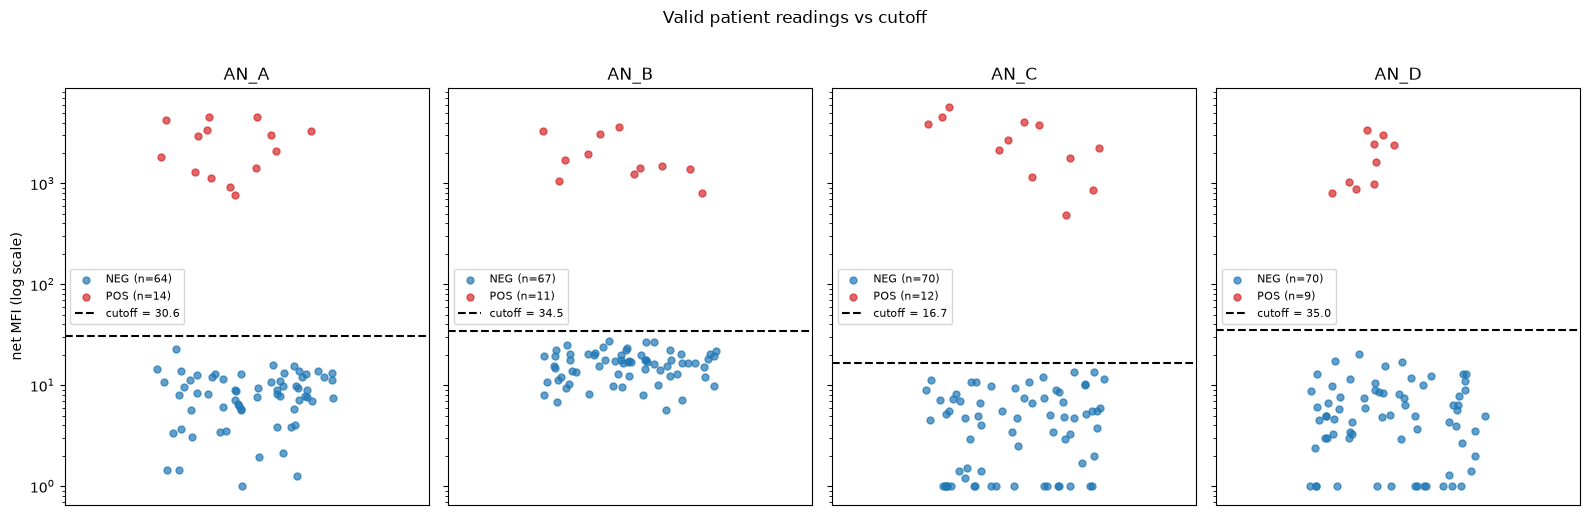

In [106]:
pat = results[(results["sample_type"] == "patient") & results["valid"]]
analytes = sorted(results["analyte"].unique())
rng = np.random.default_rng(42)
colors = {"NEG": "tab:blue", "POS": "tab:red"}

fig, axes = plt.subplots(1, len(analytes), figsize=(16, 5), sharey=True)
for ax, analyte in zip(axes, analytes):
    d = pat[pat["analyte"] == analyte]
    for call, color in colors.items():
        s = d[d["call"] == call]
        jitter = rng.uniform(-0.25, 0.25, size=len(s))
        ax.scatter(jitter, s["net_mfi"].clip(lower=1), s=25, alpha=0.7,
                   color=color, label=f"{call} (n={len(s)})")
    cutoff = cutoffs[analyte]
    if pd.notna(cutoff):
        ax.axhline(cutoff, linestyle="--", color="black", label=f"cutoff = {cutoff:.1f}")
    ax.set_yscale("log")
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([])
    ax.set_title(analyte)
    ax.legend(loc="center left", fontsize=8)
axes[0].set_ylabel("net MFI (log scale)")
fig.suptitle("Valid patient readings vs cutoff", y=1.02)
fig.tight_layout()
plt.show()

**Your answer - reading the plots.** In 3-4 sentences, what do these three charts tell the lab (is the run trustworthy? what would you check next?). Also: the standard curve is not a perfect straight line in log-log - why, and which curve model do labs normally use instead?

> Os gráficos indicam que a run é confiável: no mapa da placa, os padrões, positivos e negativos se comportam como esperado, e no gráfico de pacientes há um vão grande entre os negativos e os positivos, sem nenhum paciente perto do cutoff. Em seguida, eu verificaria as leituras inválidas (poucas beads ou sem valor) para ver se concentram em algum analito ou região da placa, e também os poços de branco, porque são apenas dois e o valor deles desloca todas as medições.
>
> A curva padrão não é uma reta perfeita porque o sinal satura nas concentrações altas: a cada vez que a concentração dobra, o sinal sobe menos que da vez anterior, e por isso o R² ficou em torno de 0,95 e não em 1. Os laboratórios costumam usar a curva logística de 4 parâmetros (4PL), ou a de 5 parâmetros (5PL), que tem formato de S e descreve o piso, o teto, o ponto de inflexão e a inclinação.

---
# Part 5 - FastAPI backend (+ optional front-end)

Work in the `app/` folder (not in the notebook):

| file | state | your job |
|---|---|---|
| `app/schemas.py` | provided | read it; finish the `TODO` (duplicate wells / sample ids -> HTTP 422) |
| `app/analysis.py` | stubs | move your **Part 3** logic here as `clean_readings()` and `analyze()` (same rules) |
| `app/main.py` | skeleton | storage class + 4 endpoints |
| `tests/test_api.py` | provided | must pass: `pytest -q`. Add **2-3 tests of your own** |

### The API contract
| Method & path | Body | Success | Errors |
|---|---|---|---|
| `GET /health` | - | `200 {"status":"ok"}` *(given)* | |
| `POST /runs` | `RunCreate` (name + samples) | `201 RunOut` | `422` bad well / duplicates / empty |
| `GET /runs/{run_id}` | - | `200 RunOut` | `404` |
| `POST /runs/{run_id}/readings` | `list[ReadingIn]` (raw rows) | `200 {"added": n}` (n = rows received) | `404` |
| `GET /runs/{run_id}/results` | - | `200 ResultsOut` (one call per `(well, analyte)`, cutoffs, `run_valid`) | `404`; `409` if no readings uploaded yet |

Design rules: keep **HTTP in `main.py`, storage in `RunRepository`, science in `analysis.py`**; endpoints get the repository through `Depends(get_repo)` (don't rename it - tests override it); runs are kept in memory.

Run it with `uvicorn app.main:app --reload` and try it at http://127.0.0.1:8000/docs.

### Bonus (optional)
`static/index.html` is served at `/ui`. Make it a tiny page that asks for a run id, calls `/runs/{id}/results`, and draws the 8x12 plate coloured by call (POS/NEG/INVALID) for a chosen analyte - plain HTML + `fetch`, no framework required. (Using a framework is fine, but be ready to explain it.)

In [ ]:
# Smoke test straight from the notebook (works once your endpoints exist)
from fastapi.testclient import TestClient
from app.main import app

client = TestClient(app)
print(client.get("/health").json())

**Your answer - design questions** (2-3 sentences each)

> 1. Why use `Depends(get_repo)` instead of a global variable inside the endpoint functions? _(write here)_
>
> 2. Why keep the analysis in `analysis.py` instead of inside the endpoint? What did that make easier? _(write here)_
>
> 3. Why `409` (and not `404` or `400`) when results are requested before readings exist? _(write here)_
>
> 4. If we swapped the in-memory dict for SQLite tomorrow, which files change and which do not? _(write here)_

---
# Part 6 - System design  *(in `DESIGN_ANSWER.md`)*
Answer the scenario in **`DESIGN_ANSWER.md`** (about one page; bullets and a simple ASCII/Mermaid diagram are fine). You will present it in the interview.

# Part 7 - Wrap-up
* Fill `AI_LOG.md`.
* *Restart kernel & Run All* - the notebook should run top to bottom without errors.
* `pytest -q` is green.
* Commit and push; send us the link. **Do not** include data that isn't in this repo.